<a href="https://colab.research.google.com/github/neurostatslab/error-in-variables-garon-2026/blob/main/demo_notebooks/005_figure2_demo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
%%capture
!git clone https://github.com/neurostatslab/error-in-variables-garon-2026.git
!pip install -e ./error-in-variables-garon-2026

#### RESTART SESSION AFTER RUNNING

In [ ]:
!pip uninstall -y -q jax-cuda13-plugin jax-cuda13-pjrt
!pip install -q "jax[cuda12]==0.6.0" "jaxlib==0.6.0"
import jax
from jax import config
config.update("jax_enable_x64", True)

import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt

import time

import tqdm
from functools import partialmethod
from typing import Literal

from eiv import utils
from eiv.core import EIV

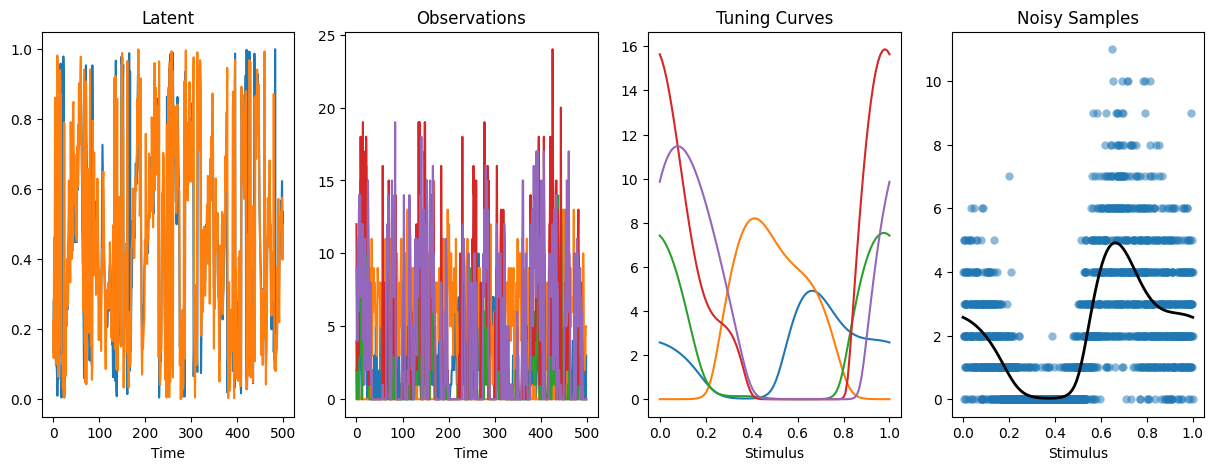

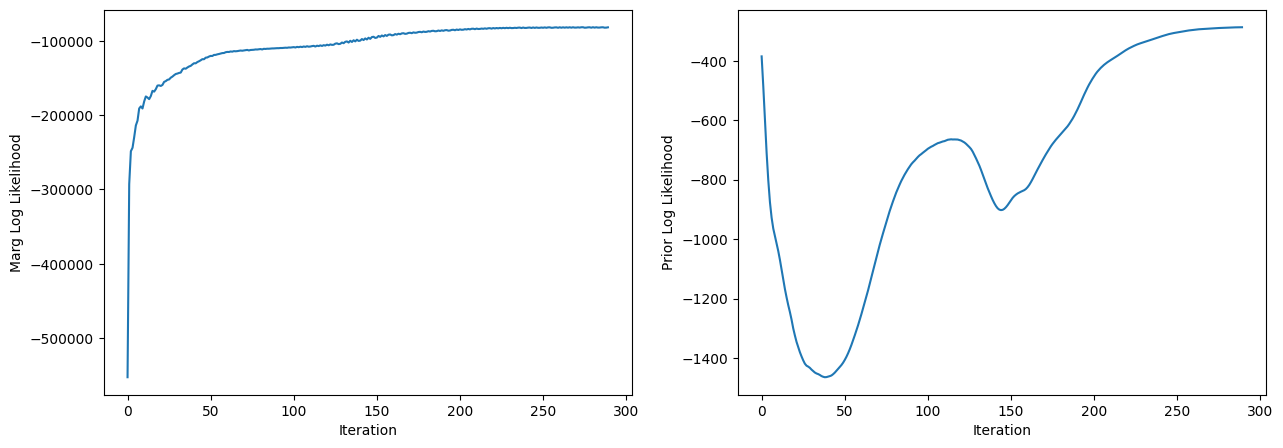

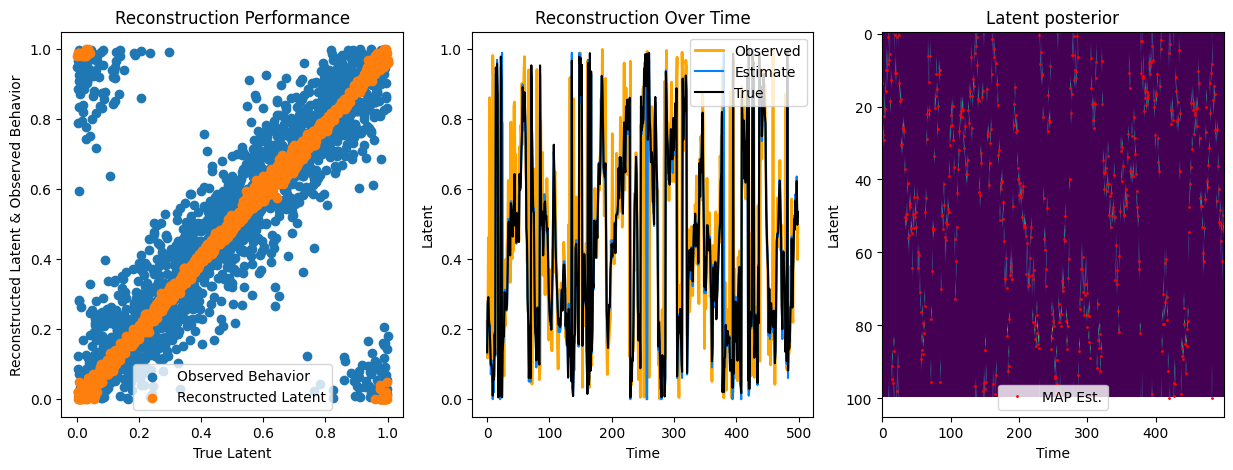

In [ ]:
gen_kappa = 3.
num_dims = 1
model = EIV(len_scale = .2,
                out_scale = 100.,
                kappa = gen_kappa,
                num_dims = 1,
                num_neurons=30)

# Simulate Data
xs_true, y_and_s = model.simulate(num_steps=2000, key = jax.random.PRNGKey(8), autocorrelated=True, x_velocity=.1)

OPT_KEY = jax.random.PRNGKey(int(5))
INIT_KEY = jax.random.PRNGKey(int(7))
opt_params = {
        "opt_key": OPT_KEY,
        "init_key": INIT_KEY,
        "tol_loss":5e-5,
        "minibatch":True,
        "batch_size":1000,
        "lr": 1e0,
    }

# Visualize Data
utils.plot_simulated_data_1D(xs_true, model.true_params, y_and_s, model);

model.fit(y_and_s, "adam", opt_params)
utils.plot_objhist(model);


x_grid = utils.make_xgrid(1, 100, 1.)
true_tunings = model.observation.mapping(model.true_params, x_grid)[0].T
utils.plot_latent_recon_sim(model, y_and_s, xs_true)

100%|██████████| 8000/8000 [00:17<00:00, 459.37it/s]


Run: 0/40


100%|██████████| 8000/8000 [00:15<00:00, 523.65it/s]


Run: 1/40


100%|██████████| 8000/8000 [00:15<00:00, 512.45it/s]


Run: 2/40


... (71 outputs left out)

Run: 38/40


100%|██████████| 8000/8000 [00:16<00:00, 480.86it/s]


Run: 39/40


<Axes: xlabel='Kappa', ylabel='Heldout MLL'>

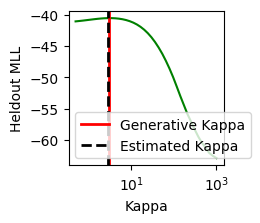

In [ ]:
scores = utils.cross_val_kappa(y_and_s, resolution = 40)
utils.plot_kappa_sweep_fig2(scores, gen_kappa = gen_kappa, resolution = 40, kappa_bounds = [0.5, 1000])

/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:3824: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


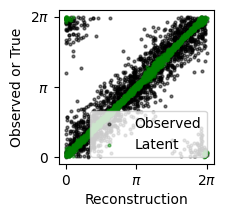

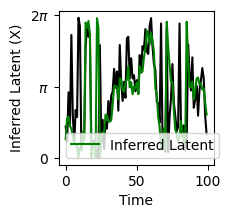

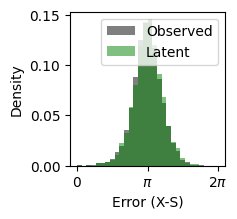

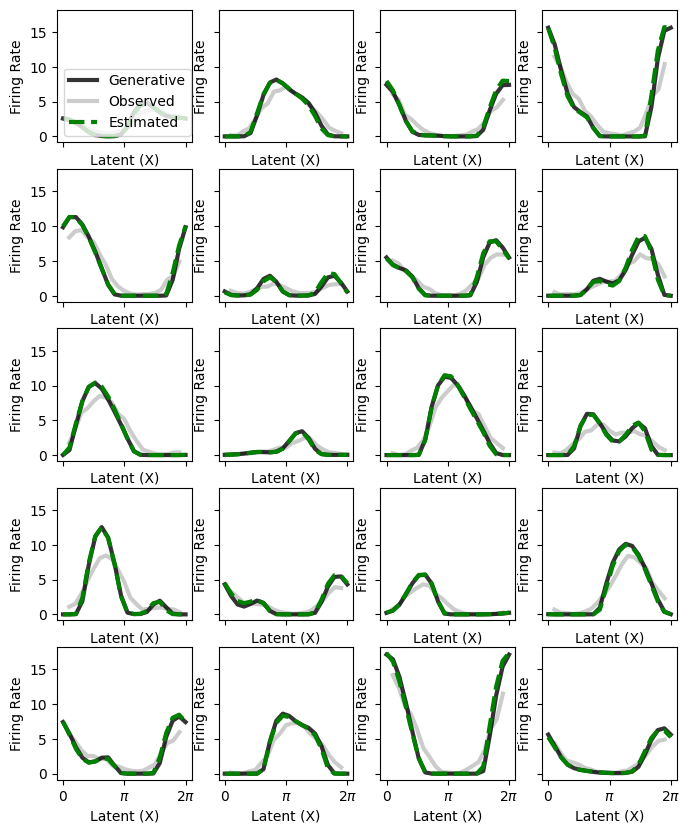

In [ ]:
utils.plot_recon_fig2(model, y_and_s, xs_gen = xs_true)
utils.plot_behav_fig2(model, y_and_s, xs_gen = xs_true, window = [0, 100])
utils.plot_hist_fig2(model, y_and_s, xs_gen = xs_true, grid_reso=100, grid_max = 1)
utils.plot_tuning_fig2(model, y_and_s);